# Learned matrices vs physics matrices for two coupled H₃ surfaces

**Paper being tested:** Shu, Varga, Zhang, Meng, Parameswaran, Zhou & Truhlar, *Learning Multiple Potential Energy Surfaces by Automated Discovery of a Compatible Representation*, J. Chem. Theory Comput. **2025**, 21, 3342–3352.

### What their method (CDNN) does
1. Input: the three internuclear distances.
2. A feed-forward network (GELU activations) outputs the unique elements of a small symmetric matrix **Ω**, the *compatible potential energy matrix* (CPEM). For two states that is Ω₁₁, Ω₂₂, Ω₁₂.
3. **Ω is diagonalised**, and its eigenvalues are compared with the adiabatic energies. The loss is the mean squared eigenvalue error plus a small L2 penalty on the weights (their eq. 5).

The matrix is never told to be diabatic, so it needs no wavefunctions, couplings or diabatic restraints. Because the energies come out as eigenvalues, two states can touch at a conical intersection without the network having to reproduce a cusp. Fitting each surface separately cannot do that; it produces an artificial avoided crossing or a double crossing (their Fig. 1).

### Why H₃ is the right place to compare it with our earlier work
The London equation we used before *is* a 2 × 2 matrix of exactly this kind. In the covalent valence-bond basis:

$$\Omega^{\rm London}=\Big(\textstyle\sum_{ij}Q_{ij}\Big)\mathbf 1+\begin{pmatrix}a&b\\ b&-a\end{pmatrix},\quad a=J_{12}-\tfrac12(J_{13}+J_{23}),\ \ b=\tfrac{\sqrt3}{2}(J_{13}-J_{23}),$$

with Q = (¹E + ³E)/2 and J = (¹E − ³E)/2 taken from the exact H₂ singlet and triplet curves. Its lower eigenvalue is the London ground state used in the earlier notebooks, and its upper eigenvalue is a prediction of the *excited* state that we never checked.

So three matrices can be put side by side on the same two states:

| Model | Matrix elements come from | H₃ data |
|---|---|---|
| **London** | exact H₂ curves, symmetry-adapted | none |
| **CDNN** | a 256-128-64 GELU network of the three distances (as in the paper) | training set |
| **London-informed CDNN** (ours) | the London matrix plus small learned corrections that keep its symmetry: a LEPS Sato function d(r) and three-body corrections to Q and J that vanish when any atom leaves | training set |

plus two controls:
- **Independent-surface network** (the paper's negative control): the same network predicting the two energies directly, with no matrix.
- **CDNN + permutations:** CDNN trained on all six atom permutations of every training geometry, the simplest way to add the permutation symmetry the paper says one would want in practice.

### Plan
- **Part A** reproduces the paper's H₃ test: a 2D cut through the conical intersection with r₂₃ fixed at 1.08 Å and r₁₂, r₁₃ from 0.88 to 1.40 Å.
- **Part B** moves to the global geometry set of the earlier notebooks (collinear and bent, out to dissociation) and asks how many H₃ points each model needs.
- **Part C** checks the two symmetry properties a physical H₃ surface must have: exact degeneracy at every equilateral geometry, and invariance to swapping identical atoms.

**References** are FCI/cc-pVDZ for the two lowest doublets (spin enforced), the same level as the ladder notebook. The paper used SA-CASSCF/def2-QZVP, so absolute numbers differ but the test is the same.

In [1]:
import time, os, numpy as np
import torch
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
KCAL_PER_EV = 23.0605
C_REF, C_LON, C_CDNN, C_IND, C_HYB, C_PERM = '#3d3d3a', '#2a78d6', '#eb6834', '#e87ba4', '#1baf7a', '#eda100'
STYLE_B = [('CDNN', '#eb6834', '-'), ('CDNN + permutations', '#eda100', '-'), ('Independent NN', '#e87ba4', '--'), ('London-informed CDNN', '#1baf7a', '-')]
DIVERGE = LinearSegmentedColormap.from_list('div', ['#2a78d6', '#e9e8e4', '#eb6834'])
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e4e3df', 'grid.linewidth': 0.6,
                     'lines.linewidth': 2, 'font.size': 10, 'legend.frameon': False})
torch.set_num_threads(os.cpu_count())

## 1 · Reference data

Generated by the functions below; the results are cached in `h3_two_state_refs.npz` (about 10 minutes to regenerate). Geometries are stored as the three distances (r₁₂, r₁₃, r₂₃).

In [2]:
"""Two lowest doublet states of H3 by FCI/cc-pVDZ, plus H atom and H2 singlet/triplet curves."""
import time, numpy as np
from pyscf import gto, fci, ao2mo

BASIS = 'cc-pvdz'

def fci_states(xyz, charge, nelec, nroots, ss):
    """Lowest nroots states with <S^2> = ss. Orbitals: eigenvectors of the one-electron Hamiltonian
    (FCI in the full orbital space does not depend on that choice)."""
    atoms = '; '.join(f'H {x:.8f} {y:.8f} 0' for x, y in xyz)
    mol = gto.M(atom=atoms, basis=BASIS, charge=charge, spin=nelec[0] - nelec[1], verbose=0)
    h = mol.intor('int1e_kin') + mol.intor('int1e_nuc')
    S = mol.intor('int1e_ovlp')
    L = np.linalg.cholesky(S)
    Li = np.linalg.inv(L)
    e1, Cp = np.linalg.eigh(Li @ h @ Li.T)
    C = Li.T @ Cp
    norb = C.shape[1]
    if sum(nelec) == 1:
        return e1[:nroots] + mol.energy_nuc()
    eri = ao2mo.restore(1, ao2mo.kernel(mol, C), norb)
    solver = fci.addons.fix_spin_(fci.direct_spin1.FCI(), ss=ss, shift=0.5)
    solver.conv_tol = 1e-10
    e, _ = solver.kernel(C.T @ h @ C, eri, norb, nelec, ecore=mol.energy_nuc(), nroots=nroots)
    return np.atleast_1d(e)[:nroots]

def tri_xy(r12, r13, r23):
    """Planar coordinates for H1, H2, H3 from the three distances (H2 at origin, H3 on x)."""
    x = (r12 ** 2 - r13 ** 2 + r23 ** 2) / (2 * r23)
    y = np.sqrt(max(r12 ** 2 - x ** 2, 0.0))
    return [(x, y), (0.0, 0.0), (r23, 0.0)]



In [3]:
if not os.path.exists('h3_two_state_refs.npz'):
    raise SystemExit('run refs_h3.py first (or place h3_two_state_refs.npz next to this notebook)')
ref = dict(np.load('h3_two_state_refs.npz'))
EV = 27.211386
to_ev = lambda E: (E - 3 * ref['E_H']) * EV                  # energies relative to three H atoms
R_cut, V_cut = ref['cut_R'], to_ev(ref['cut_E'])
R_glob, V_glob, geo_glob = ref['glob_R'], to_ev(ref['glob_E']), ref['glob_geo']
print(f'cut: {len(R_cut)} geometries | global: {len(R_glob)} geometries')
gap_d3h = V_glob[(geo_glob[:, 2] == 60) & (geo_glob[:, 0] == geo_glob[:, 1])]
print('FCI gap at the equilateral geometries of the global set (meV):', np.round((gap_d3h[:, 1] - gap_d3h[:, 0]) * 1000, 4))

cut: 441 geometries | global: 499 geometries
FCI gap at the equilateral geometries of the global set (meV): [0. 0. 0. 0. 0. 0. 0. 0. 0.]


## 2 · The models

All learned models are trained the same way: Adam with a cosine learning-rate schedule, the paper's cost function (eq. 5), and the epoch with the lowest validation error kept. The paper ran 300 random restarts and kept the best; here each model gets 3 restarts, selected on the validation set, never the test set.

In [4]:
"""Two-state H3 models: London, LEPS, CDNN (Shu et al. JCTC 2025), independent-surface NN, and a
London-informed CDNN. Inputs are the three distances (r12, r13, r23) in Angstrom; energies in eV relative to 3 H."""
import numpy as np
import torch
from scipy.interpolate import CubicSpline

torch.set_default_dtype(torch.float64)
EV = 27.211386          # eV per hartree
BOHR = 0.529177
PAIRS = [(0, 1), (0, 2), (1, 2)]   # columns of R: r12, r13, r23

# ---------------------------------------------------------------- fragment curves (exact H2 singlet / triplet)
class H2Curves:
    def __init__(self, ref):
        r = ref['r_di']
        self.rmax = r[-1]
        self.S = CubicSpline(r, (ref['H2_S'] - 2 * ref['E_H']) * EV)
        self.T = CubicSpline(r, (ref['H2_T'] - 2 * ref['E_H']) * EV)
    def __call__(self, R):
        R = np.asarray(R)
        far = R >= self.rmax
        Rc = np.minimum(R, self.rmax)
        return np.where(far, 0.0, self.S(Rc)), np.where(far, 0.0, self.T(Rc))

def eig2(o11, o22, o12, eps=1e-12):
    """Eigenvalues of a symmetric 2x2 matrix, lower first (works for numpy arrays and torch tensors)."""
    lib = torch if isinstance(o11, torch.Tensor) else np
    m, d = (o11 + o22) / 2, (o11 - o22) / 2
    s = lib.sqrt(d * d + o12 * o12 + eps)
    return m - s, m + s

def london_matrix(S, T):
    """2x2 covalent VB (London) matrix from per-pair singlet/triplet energies S, T of shape (N, 3).
    Q = (S+T)/2 on the diagonal; (a, b) transform as the E irrep, so the conical intersection at D3h is exact."""
    Q, J = (S + T) / 2, (S - T) / 2
    q = Q.sum(1)
    a = J[:, 0] - (J[:, 1] + J[:, 2]) / 2
    b = (np.sqrt(3) / 2) * (J[:, 1] - J[:, 2])
    return q + a, q - a, b            # Omega_11, Omega_22, Omega_12

# ---------------------------------------------------------------- learned models
def mlp(n_in, hidden, n_out):
    layers, d = [], n_in
    for h in hidden:
        layers += [torch.nn.Linear(d, h), torch.nn.GELU()]
        d = h
    layers.append(torch.nn.Linear(d, n_out))
    return torch.nn.Sequential(*layers)

class CDNN(torch.nn.Module):
    """Compatibilization by deep neural network: distances -> MLP -> dense 2x2 CPEM -> eigenvalues."""
    def __init__(self, hidden=(256, 128, 64)):
        super().__init__()
        self.net = mlp(3, hidden, 3)
    def cpem(self, X):
        o = self.net(X)
        return o[:, 0], o[:, 1], o[:, 2]
    def forward(self, X):
        return torch.stack(eig2(*self.cpem(X)), 1)

class Independent(torch.nn.Module):
    """Same network, but predicting the two adiabatic energies directly (no matrix, no diagonalisation)."""
    def __init__(self, hidden=(256, 128, 64)):
        super().__init__()
        self.net = mlp(3, hidden, 2)
    def forward(self, X):
        return self.net(X)

def slater_t(r):
    p = r / BOHR
    return torch.exp(-p) * (1 + p + p * p / 3)

class LondonInformed(torch.nn.Module):
    """London matrix from exact H2 curves, plus learned corrections that keep its symmetry and limits:
    (1) a LEPS Sato function d(r) per pair (exact H2 + H limit is preserved),
    (2) three-body corrections to Q and J for each pair, scaled by the overlaps with the third atom,
        so they vanish whenever any atom leaves. (a, b) still transform as E, so the D3h intersection stays exact."""
    def __init__(self, hidden=(32, 32)):
        super().__init__()
        self.sato = mlp(1, hidden, 1)
        self.three = mlp(1, hidden, 2)
    def matrix(self, R, S, T):
        sR = slater_t(R)                                         # (N, 3) decaying envelopes
        d = torch.tanh(self.sato(R.reshape(-1, 1))).reshape(R.shape) * 0.9 * sR / (sR + 0.05)
        Q = ((1 + d) * S + (1 - d) * T) / 2 / (1 + d)
        J = ((1 + d) * S - (1 - d) * T) / 2 / (1 + d)
        # three-body envelope for pair (i,j): s_ij * (s_ik + s_jk) / 2, zero if any of the three atoms leaves
        env = sR * torch.stack([sR[:, 1] + sR[:, 2], sR[:, 0] + sR[:, 2], sR[:, 0] + sR[:, 1]], 1) / 2
        c = self.three(R.reshape(-1, 1)).reshape(R.shape[0], 3, 2)
        Q = Q + c[..., 0] * env
        J = J + c[..., 1] * env
        q = Q.sum(1)
        a = J[:, 0] - (J[:, 1] + J[:, 2]) / 2
        b = (np.sqrt(3) / 2) * (J[:, 1] - J[:, 2])
        return q + a, q - a, b
    def start_at_physics(self):
        # zero the output layers so training starts from the plain London matrix
        for net in (self.sato, self.three):
            torch.nn.init.zeros_(net[-1].weight); torch.nn.init.zeros_(net[-1].bias)
    def forward(self, X, S, T):
        return torch.stack(eig2(*self.matrix(X, S, T)), 1)

def train(model, X, Y, S=None, T=None, epochs=4000, lr=1e-3, alpha2=1e-6, seed=0, Xv=None, Yv=None, Sv=None, Tv=None):
    """Adam on the CDNN cost (eq. 5 of the paper): mean squared eigenvalue error + alpha2/2 * sum of squared weights.
    Returns the model at the epoch with the lowest validation error when a validation set is given."""
    torch.manual_seed(seed)
    for p in model.parameters():
        if p.dim() > 1:
            torch.nn.init.xavier_normal_(p)
        else:
            torch.nn.init.zeros_(p)
    if hasattr(model, 'start_at_physics'):
        model.start_at_physics()
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, epochs)
    call = (lambda m, x, s, t: m(x)) if S is None else (lambda m, x, s, t: m(x, s, t))
    best, state = np.inf, None
    for ep in range(epochs):
        opt.zero_grad()
        loss = ((call(model, X, S, T) - Y) ** 2).mean() / 2
        loss = loss + alpha2 / 2 * sum((p ** 2).sum() for n, p in model.named_parameters() if 'weight' in n)
        loss.backward()
        opt.step(); sched.step()
        if Xv is not None and (ep % 50 == 0 or ep == epochs - 1):
            with torch.no_grad():
                v = (call(model, Xv, Sv, Tv) - Yv).abs().mean().item()
            if v < best:
                best, state = v, {k: x.clone() for k, x in model.state_dict().items()}
    if state is not None:
        model.load_state_dict(state)
    return model


In [5]:
curves = H2Curves(ref)
def ST(R):
    S, T = curves(R)
    return torch.tensor(S), torch.tensor(T)
def london(R):
    S, T = curves(R)
    return np.stack(eig2(*london_matrix(S, T)), 1)

PERMS = [[0, 1, 2], [0, 2, 1], [1, 0, 2], [1, 2, 0], [2, 0, 1], [2, 1, 0]]   # all six atom permutations act on (r12, r13, r23)
def augment(R, V):
    return np.concatenate([R[:, p] for p in PERMS]), np.concatenate([V] * len(PERMS))

def fit_model(kind, Rtr, Vtr, Rva, Vva, trials=3, epochs=4000):
    # returns a predict(R) -> (N, 2) energies in eV
    if kind == 'cdnn_perm':                       # CDNN trained on every permutation of every training geometry
        (Rtr, Vtr), (Rva, Vva) = augment(Rtr, Vtr), augment(Rva, Vva)
    mu, sd = Rtr.mean(0), Rtr.std(0) + 1e-9
    tx = lambda R: torch.tensor((R - mu) / sd)
    best = (np.inf, None)
    for t in range(trials):
        if kind == 'hybrid':
            m = LondonInformed()
            S, T = ST(Rtr); Sv, Tv = ST(Rva)
            m = train(m, torch.tensor(Rtr), torch.tensor(Vtr), S, T, epochs=epochs, lr=3e-3, seed=t,
                      Xv=torch.tensor(Rva), Yv=torch.tensor(Vva), Sv=Sv, Tv=Tv)
            pred = lambda R, m=m: m(torch.tensor(R), *ST(R)).detach().numpy()
        else:
            m = CDNN() if kind in ('cdnn', 'cdnn_perm') else Independent()
            m = train(m, tx(Rtr), torch.tensor(Vtr), epochs=epochs, lr=1e-3, seed=t, Xv=tx(Rva), Yv=torch.tensor(Vva))
            pred = lambda R, m=m: m(tx(R)).detach().numpy()
        err = np.abs(pred(Rva) - Vva).mean()
        if err < best[0]:
            best = (err, pred, m)
    return best[1], best[2], (mu, sd)

def scores(pred, R, V):
    e = pred(R) - V
    return np.abs(e).mean(0) * 1000, np.sqrt((e ** 2).mean(0)) * KCAL_PER_EV     # MUE (meV), RMSE (kcal/mol) per state

## Part A · The paper's test: a cut through the conical intersection

r₂₃ = 1.08 Å, r₁₂ and r₁₃ from 0.88 to 1.40 Å (21 × 21 grid). The two states are exactly degenerate at r₁₂ = r₁₃ = 1.08 Å. Random 60 / 20 / 20 split into train, validation and test. The paper reports mean unsigned errors in meV; both MUE and RMSE are given here.

In [6]:
rng = np.random.default_rng(0)
perm = rng.permutation(len(R_cut))
itr, iva, ite = perm[:265], perm[265:353], perm[353:]
t0 = time.time()
A = {'London': (london, None)}
for kind, name in [('cdnn', 'CDNN'), ('cdnn_perm', 'CDNN + permutations'), ('indep', 'Independent NN'), ('hybrid', 'London-informed CDNN')]:
    p, m, norm = fit_model(kind, R_cut[itr], V_cut[itr], R_cut[iva], V_cut[iva])
    A[name] = (p, m, norm) if kind == 'cdnn' else (p, m)
    print(f'{name} trained ({time.time() - t0:.0f} s)')

D3H = np.array([[1.08, 1.08, 1.08]])
swap = lambda R: R[:, [1, 0, 2]]                    # exchange atoms 2 and 3: r12 <-> r13
print(f'\n{"model":22s} {"MUE meV (S0, S1)":>18s} {"RMSE kcal/mol (S0, S1)":>24s} {"gap at D3h (meV)":>17s} {"swap error (meV)":>17s}')
for name, v in A.items():
    p = v[0]
    mue, rm = scores(p, R_cut[ite], V_cut[ite])
    g = (p(D3H)[0, 1] - p(D3H)[0, 0]) * 1000
    sw = np.abs(p(R_cut) - p(swap(R_cut))).mean() * 1000
    print(f'{name:22s} {mue[0]:8.1f} {mue[1]:8.1f}   {rm[0]:10.2f} {rm[1]:10.2f}   {g:14.2f}   {sw:14.2f}')

CDNN trained (40 s)


CDNN + permutations trained (197 s)


Independent NN trained (234 s)


London-informed CDNN trained (276 s)

model                    MUE meV (S0, S1)   RMSE kcal/mol (S0, S1)  gap at D3h (meV)  swap error (meV)
London                    304.9    486.6         7.99      12.29             0.00             0.00
CDNN                        2.7      2.8         0.07       0.07             0.20             0.77
CDNN + permutations         2.2      1.8         0.06       0.05             2.71             1.29
Independent NN              5.4      4.5         0.31       0.27           291.21             2.78
London-informed CDNN        5.4      9.0         0.15       0.28             0.00             0.00


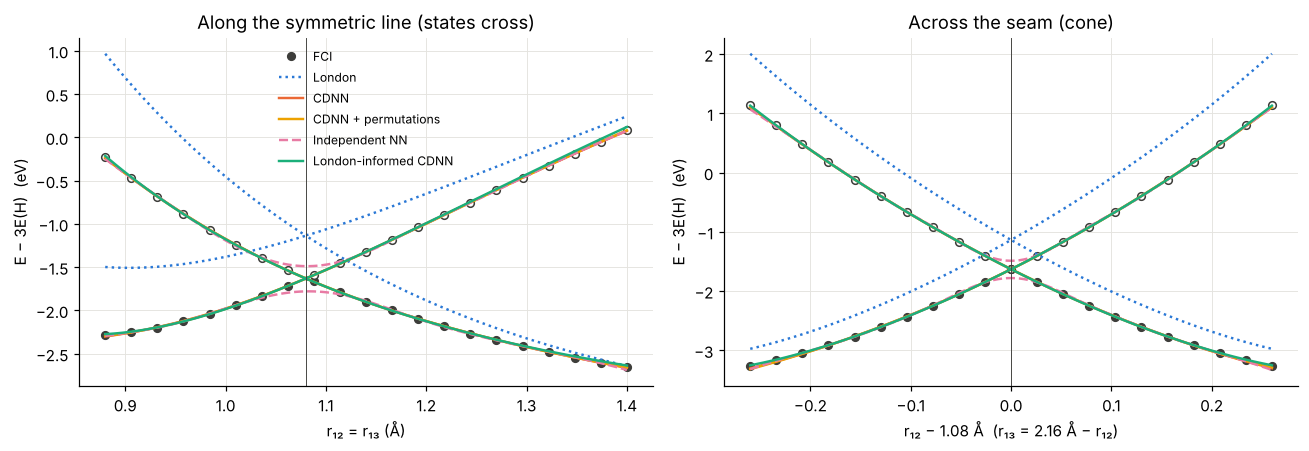

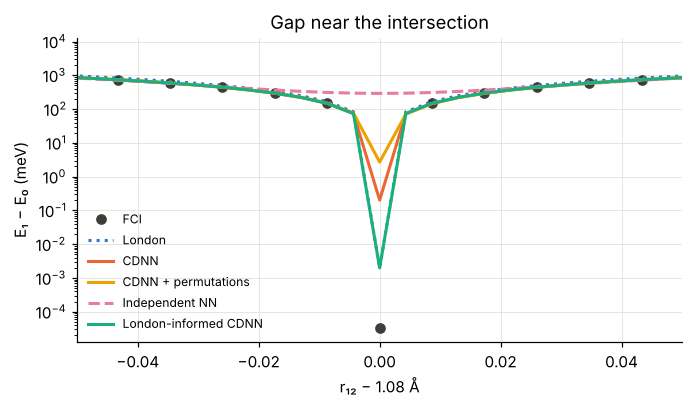

In [7]:
# two 1D slices through the intersection: along r12 = r13 (symmetric) and across it (r12 + r13 = 2.16 A)
s = np.linspace(0.88, 1.40, 121)
sl1 = np.c_[s, s, np.full_like(s, 1.08)]
dlt = np.linspace(-0.26, 0.26, 121)
sl2 = np.c_[1.08 + dlt, 1.08 - dlt, np.full_like(dlt, 1.08)]
exact1 = np.array([fci_states(tri_xy(*d), 0, (2, 1), 2, 0.75) for d in sl1[::6]])
exact2 = np.array([fci_states(tri_xy(*d), 0, (2, 1), 2, 0.75) for d in sl2[::6]])
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, sl, x, ex, xl in [(axes[0], sl1, s, exact1, 'r₁₂ = r₁₃ (Å)'), (axes[1], sl2, dlt, exact2, 'r₁₂ − 1.08 Å  (r₁₃ = 2.16 Å − r₁₂)')]:
    ax.plot(x[::6], to_ev(ex)[:, 0], 'o', color=C_REF, ms=5, label='FCI')
    ax.plot(x[::6], to_ev(ex)[:, 1], 'o', color=C_REF, ms=5, mfc='white')
    for name, col, ls in [('London', C_LON, ':'), ('CDNN', C_CDNN, '-'), ('CDNN + permutations', C_PERM, '-'), ('Independent NN', C_IND, '--'), ('London-informed CDNN', C_HYB, '-')]:
        E = A[name][0](sl)
        ax.plot(x, E[:, 0], color=col, ls=ls, lw=1.6, label=name)
        ax.plot(x, E[:, 1], color=col, ls=ls, lw=1.6)
    ax.axvline(1.08 if ax is axes[0] else 0, color=C_REF, lw=0.6)
    ax.set(xlabel=xl, ylabel='E − 3E(H)  (eV)')
axes[0].set_title('Along the symmetric line (states cross)'); axes[1].set_title('Across the seam (cone)')
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig('cdnn_fig1_ci_slices.png', bbox_inches='tight'); plt.show()

# zoom on the intersection: the gap |E1 - E0| along the cross-seam slice, log scale
fig, ax = plt.subplots(figsize=(6.4, 3.8))
ex_gap = to_ev(np.array([fci_states(tri_xy(*d), 0, (2, 1), 2, 0.75) for d in sl2[50:71:2]]))
ax.semilogy(dlt[50:71:2], (ex_gap[:, 1] - ex_gap[:, 0]) * 1000, 'o', color=C_REF, label='FCI')
for name, col, ls in [('London', C_LON, ':'), ('CDNN', C_CDNN, '-'), ('CDNN + permutations', C_PERM, '-'), ('Independent NN', C_IND, '--'), ('London-informed CDNN', C_HYB, '-')]:
    E = A[name][0](sl2)
    ax.semilogy(dlt, np.maximum((E[:, 1] - E[:, 0]) * 1000, 1e-3), color=col, ls=ls, label=name)
ax.set(xlim=(-0.05, 0.05), xlabel='r₁₂ − 1.08 Å', ylabel='E₁ − E₀ (meV)', title='Gap near the intersection')
ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig('cdnn_fig2_gap.png', bbox_inches='tight'); plt.show()

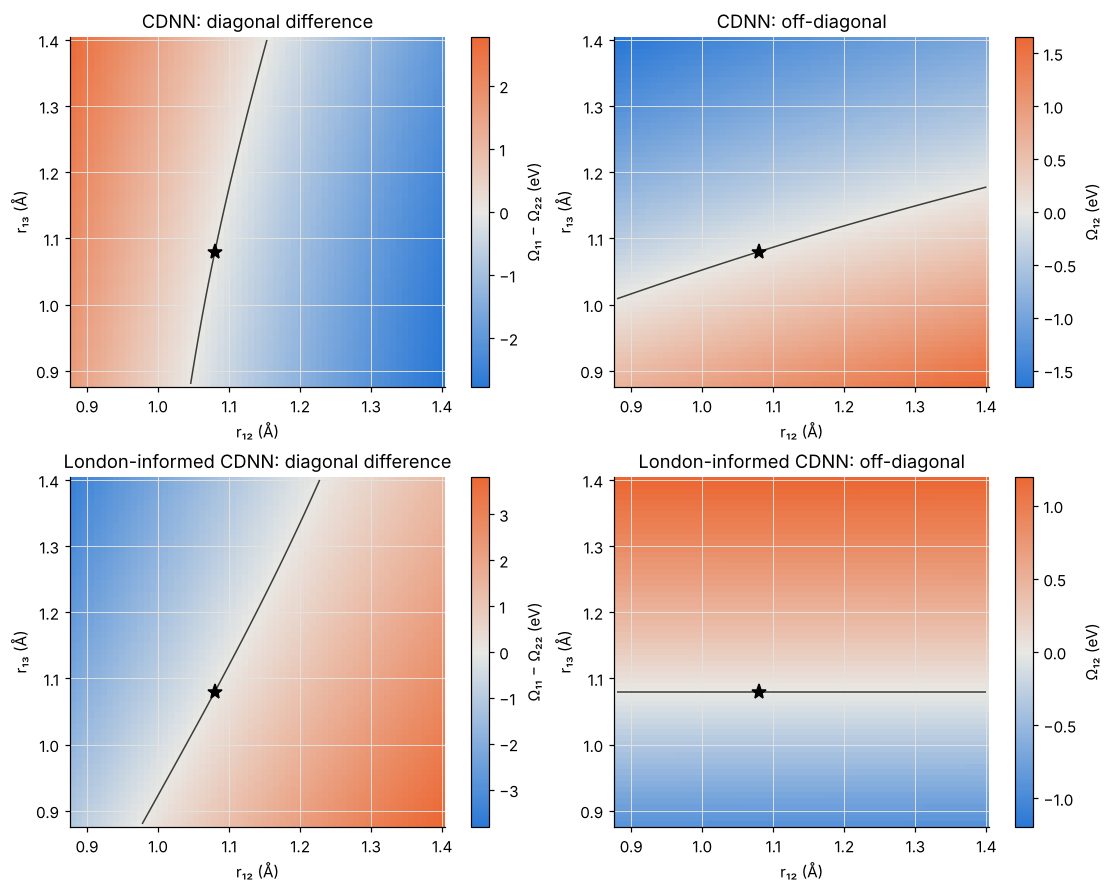

CDNN Ω12 range over the cut: -1.652 to 1.612 eV; changes sign: True


In [8]:
# what the matrices look like: CDNN's discovered CPEM vs the London-informed matrix (paper Fig. 4c,d)
g = np.linspace(0.88, 1.40, 61)
G1, G2 = np.meshgrid(g, g, indexing='ij')
Rg = np.c_[G1.ravel(), G2.ravel(), np.full(G1.size, 1.08)]
p, m, (mu, sd) = A['CDNN']
with torch.no_grad():
    c11, c22, c12 = [x.numpy().reshape(G1.shape) for x in m.cpem(torch.tensor((Rg - mu) / sd))]
hm = A['London-informed CDNN'][1]
with torch.no_grad():
    S, T = ST(Rg)
    h11, h22, h12 = [x.numpy().reshape(G1.shape) for x in hm.matrix(torch.tensor(Rg), S, T)]
fig, axes = plt.subplots(2, 2, figsize=(10, 8), layout='constrained')
for row, (o11, o22, o12, name) in enumerate([(c11, c22, c12, 'CDNN'), (h11, h22, h12, 'London-informed CDNN')]):
    lim = np.abs(o11 - o22).max()
    im = axes[row, 0].pcolormesh(G1, G2, o11 - o22, cmap=DIVERGE, vmin=-lim, vmax=lim, shading='auto')
    axes[row, 0].contour(G1, G2, o11 - o22, levels=[0], colors=C_REF, linewidths=1)
    plt.colorbar(im, ax=axes[row, 0], label='Ω₁₁ − Ω₂₂ (eV)')
    lim = max(np.abs(o12).max(), 1e-6)
    im = axes[row, 1].pcolormesh(G1, G2, o12, cmap=DIVERGE, vmin=-lim, vmax=lim, shading='auto')
    axes[row, 1].contour(G1, G2, o12, levels=[0], colors=C_REF, linewidths=1)
    plt.colorbar(im, ax=axes[row, 1], label='Ω₁₂ (eV)')
    for ax in axes[row]:
        ax.plot(1.08, 1.08, 'k*', ms=10)
        ax.set(xlabel='r₁₂ (Å)', ylabel='r₁₃ (Å)')
    axes[row, 0].set_title(f'{name}: diagonal difference'); axes[row, 1].set_title(f'{name}: off-diagonal')
plt.savefig('cdnn_fig3_cpem.png', bbox_inches='tight'); plt.show()
print(f'CDNN Ω12 range over the cut: {c12.min():.3f} to {c12.max():.3f} eV; changes sign: {c12.min() < 0 < c12.max()}')

**Reading the matrix maps.** A conical intersection needs *two* conditions at once: Ω₁₁ = Ω₂₂ and Ω₁₂ = 0, so the two zero-lines (black) must cross at the star. In the London-informed matrix they do so by symmetry, the same way a true diabatic E⊗e Hamiltonian does. The paper notes that CDNN's off-diagonal element typically does not change sign through the intersection, so its zero-gap point is only approximate; they added a sign-encouraging "topology attention" term (CTAN) for that reason.

## Part B · The global surface: how many H₃ points does each matrix need?

The geometry set of the earlier notebooks: a 16 × 16 collinear grid plus bent geometries at 60°, 90° and 120°, out to 3.6 Å. The same window as before applies: every H–H distance ≥ 0.6 Å and ground state within 0.2 Eh (5.4 eV) of three free atoms. For each training size *n*, 60 window points are held out for validation and the remaining points are the test set; two random draws per *n*.

Excited-state error is also reported for the part of the surface where S₁ lies within 2 eV of three free atoms. At compressed collinear geometries S₁ climbs to 3.5–7 eV, where it is no longer the covalent state the London matrix describes.

In [9]:
rmin = R_glob.min(1)
W = np.where((rmin >= 0.6) & (V_glob[:, 0] <= 0.2 * EV))[0]
eq_line = np.where((geo_glob[:, 2] == 60) & (geo_glob[:, 0] == geo_glob[:, 1]))[0]
print(f'{len(W)} window geometries')
ns = [25, 50, 100, 200]
MODELS_B = [('cdnn', 'CDNN'), ('cdnn_perm', 'CDNN + permutations'), ('indep', 'Independent NN'), ('hybrid', 'London-informed CDNN')]
B = {name: {n: [] for n in ns} for _, name in MODELS_B}
def low_s1(p, idx):
    # excited-state RMSE where S1 lies within 2 eV of three free atoms (the part a hot molecule can reach)
    k = idx[V_glob[idx, 1] <= 2.0]
    return np.sqrt(np.mean((p(R_glob[k])[:, 1] - V_glob[k, 1]) ** 2)) * KCAL_PER_EV
lon_scores = []
t0 = time.time()
for seed in range(2):
    pw = np.random.default_rng(10 + seed).permutation(W)
    va, pool = pw[:60], pw[60:]
    for n in ns:
        tr, te = pool[:n], pool[n:]
        if n == ns[0]:
            lon_scores.append(list(scores(london, R_glob[te], V_glob[te])[1]) + [low_s1(london, te)])
        for kind, name in MODELS_B:
            p = fit_model(kind, R_glob[tr], V_glob[tr], R_glob[va], V_glob[va])[0]
            rm = scores(p, R_glob[te], V_glob[te])[1]
            Eq = p(R_glob[eq_line])
            sw = np.abs(p(R_glob[te]) - p(swap(R_glob[te]))).mean() * 1000
            B[name][n].append((rm[0], rm[1], np.abs(Eq[:, 1] - Eq[:, 0]).mean() * 1000, sw, low_s1(p, te)))
        print(f'seed {seed} n = {n:3d} done ({time.time() - t0:.0f} s)', flush=True)
lon = np.mean(lon_scores, 0)
print(f'\nLondon (0 H3 points): S0 {lon[0]:.2f}, S1 {lon[1]:.2f}, S1 (≤ 2 eV) {lon[2]:.2f} kcal/mol RMSE')
print(f'{"model":22s} {"n":>4s} {"S0 RMSE":>8s} {"S1 RMSE":>8s} {"S1≤2eV":>8s} {"gap D3h meV":>12s} {"swap meV":>9s}')
for name, d in B.items():
    for n in ns:
        a = np.mean(d[n], 0)
        print(f'{name:22s} {n:4d} {a[0]:8.2f} {a[1]:8.2f} {a[4]:8.2f} {a[2]:12.1f} {a[3]:9.1f}')

499 window geometries


seed 0 n =  25 done (104 s)


seed 0 n =  50 done (223 s)


seed 0 n = 100 done (380 s)


seed 0 n = 200 done (591 s)


seed 1 n =  25 done (692 s)


seed 1 n =  50 done (811 s)


seed 1 n = 100 done (959 s)


seed 1 n = 200 done (1170 s)



London (0 H3 points): S0 5.86, S1 13.71, S1 (≤ 2 eV) 3.79 kcal/mol RMSE
model                     n  S0 RMSE  S1 RMSE   S1≤2eV  gap D3h meV  swap meV
CDNN                     25    21.52    19.24     7.21       1542.5    1075.9
CDNN                     50     9.56    11.55     5.44       1439.9    1111.9
CDNN                    100     3.80     4.98     1.36        192.9     873.0
CDNN                    200     2.48     2.89     0.76        160.9    1226.3
CDNN + permutations      25    11.55    18.34     4.15        731.4      30.1
CDNN + permutations      50     2.72     4.93     1.18        382.9      41.3
CDNN + permutations     100     2.10     2.99     1.09        282.3      34.7
CDNN + permutations     200     1.83     1.63     1.22        273.8      34.6
Independent NN           25    20.85    26.24     7.67       1447.8    1605.4
Independent NN           50    11.83    11.27     7.17       1368.8    1653.1
Independent NN          100     4.29     5.40     2.16        340.1  

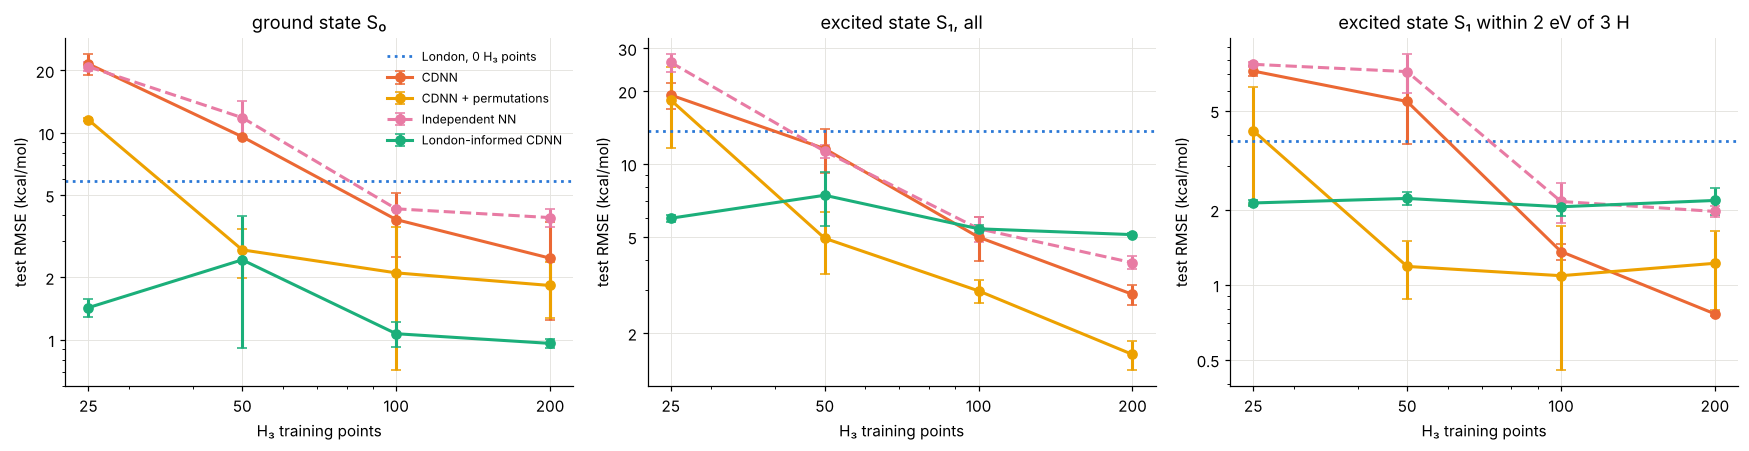

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for k, ax, st in [(0, axes[0], 'ground state S₀'), (1, axes[1], 'excited state S₁, all'), (4, axes[2], 'excited state S₁ within 2 eV of 3 H')]:
    for name, col, ls in STYLE_B:
        v = np.array([[x[k] for x in B[name][n]] for n in ns])
        ax.errorbar(ns, v.mean(1), yerr=[v.mean(1) - v.min(1), v.max(1) - v.mean(1)], color=col, ls=ls, marker='o', ms=6, capsize=3, label=name)
    ax.axhline(lon[{0: 0, 1: 1, 4: 2}[k]], color=C_LON, ls=':', lw=1.8, label='London, 0 H₃ points')
    ax.set(xscale='log', yscale='log', xlabel='H₃ training points', ylabel='test RMSE (kcal/mol)', title=st)
    ax.set_xticks(ns); ax.set_xticklabels(ns); ax.xaxis.set_minor_formatter(plt.NullFormatter())
    yt = [0.5, 1, 2, 5, 10, 20, 30]
    lo, hi = ax.get_ylim()
    yt = [t for t in yt if lo <= t <= hi]
    ax.set_yticks(yt); ax.set_yticklabels([f'{t:g}' for t in yt]); ax.yaxis.set_minor_formatter(plt.NullFormatter())
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig('cdnn_fig4_global.png', bbox_inches='tight'); plt.show()

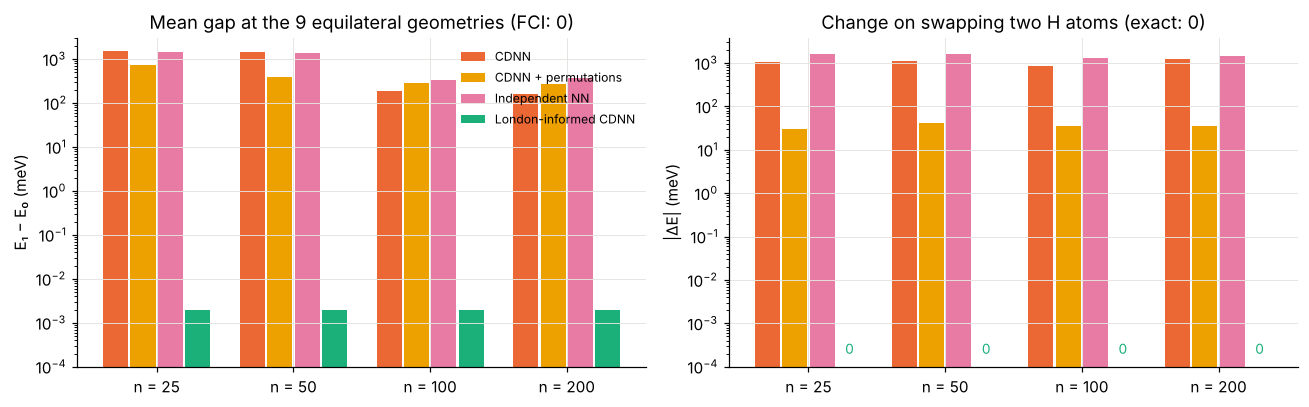

In [11]:
# Part C: symmetry. Equilateral geometries must be exactly degenerate; swapping identical atoms must not change anything.
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
x = np.arange(len(ns))
w = 0.2
for j, (name, col, _) in enumerate(STYLE_B):
    for k, ax in [(2, axes[0]), (3, axes[1])]:
        v = [np.mean([y[k] for y in B[name][n]]) for n in ns]
        ax.bar(x + (j - 1.5) * w, np.maximum(v, 1e-4), w * 0.92, color=col, label=name)
        for xi, vi in zip(x, v):
            if vi < 1e-6:
                ax.text(xi + (j - 1.5) * w, 2e-4, '0', ha='center', fontsize=9, color=col)
for ax, t, yl in [(axes[0], 'Mean gap at the 9 equilateral geometries (FCI: 0)', 'E₁ − E₀ (meV)'),
                  (axes[1], 'Change on swapping two H atoms (exact: 0)', '|ΔE| (meV)')]:
    ax.set(xticks=x, xticklabels=[f'n = {n}' for n in ns], yscale='log', ylabel=yl, title=t)
    ax.set_ylim(1e-4, None)
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig('cdnn_fig5_symmetry.png', bbox_inches='tight'); plt.show()

**Note on the symmetry plot.** The London-informed model's gap at equilateral geometries (about 0.002 meV) is the 10⁻¹² regulariser inside the square root of the 2 × 2 eigenvalue formula, not a fitted gap. Its swap error is exactly zero.

## Takeaways

### What the paper's method does well
- **CDNN reproduces their result.** On the paper's cut through the intersection it fits both states to 2.7 meV (0.07 kcal/mol). It closes the gap at the intersection to 0.2 meV, and its learned off-diagonal element does change sign there in this run (the paper saw runs where it did not, which is why they added the topology-attention term).
- **The matrix is what makes it work.** The same network predicting the two energies directly fits the data almost as well (5 meV), but leaves a 290 meV artificial avoided crossing exactly where the states should touch (their Fig. 1b, now measured).
- **With enough data it is the most flexible model here.** Trained on all atom permutations and 200 global points, CDNN reaches 1.8 kcal/mol for S₀ and 1.6 for S₁, the best excited-state result over the whole window (plain CDNN does best, 0.8, in the low-lying part).

### Where it needs help on a global surface
- **Symmetry is not built in.** Plain CDNN changes by about 1 eV when two identical atoms are relabelled, because those inputs were never in its training set. Training on all six permutations cuts that to about 35 meV but does not remove it.
- **The global intersection seam is not reproduced.** At the nine equilateral geometries the gap stays at 160–1500 meV even with permutations. A symmetric matrix of invariant-looking inputs has no reason to be degenerate at D₃ₕ; only a matrix whose elements transform as the E irrep is (the covariant-basis idea of Yin, Braams, Fu & Zhang, JCTC 2021).
- **It needs data.** Plain CDNN needs about 100–200 global points to beat the London matrix, which uses none.

### What the physics matrix adds
- **The London matrix gives topology for free:** exact degeneracy at every equilateral geometry, exact permutation symmetry, exact dissociation limits, all with zero H₃ data. It is too crude near the intersection (305 meV on the paper's cut, which sits at compressed geometries), but it is a correct *frame*.
- **The London-informed CDNN keeps that frame and learns the rest.** It reaches 1.4 kcal/mol for S₀ from 25 points and ~1 from 100, with exact symmetry at every training size. This matches what the 6-parameter LEPS Sato(r) model achieved for the ground state in the ladder notebook (1.8 at 20 points, 1.0 at 80), and now covers the excited state and the intersection too.
- **Its ceiling is the covalent space.** The excited state stops improving at about 2 kcal/mol where S₁ is within 2 eV of three free atoms, and about 5 overall. The worst points are compressed collinear geometries 3.5–7 eV up, where S₁ is no longer a covalent-structure state. That is the same lesson as water: the frame must contain the right structures (there, ionic O⁻H⁺; here, higher states).

### How this fits the earlier notebooks (ground state, same geometry window and FCI level)
| Model | H₃ points | S₀ RMSE (kcal/mol) |
|---|---|---|
| Site Hamiltonian from the electron ladder | 0 / 80 | 12.6 / 6.3 |
| London (2 × 2, exact H₂ curves) | 0 | 5.5–5.9 |
| LEPS with learned Sato(r), 6 numbers | 20 / 80 | 1.8 / 1.0 |
| CDNN (paper's architecture) | 100 / 200 | 3.8 / 2.5 |
| CDNN + permutation training | 50 / 200 | 2.7 / 1.8 |
| **London-informed CDNN** | **25 / 200** | **1.4 / 1.0** |

### The bigger picture
CDNN and the fragment-state approach are complementary, not competing. CDNN supplies the general machinery: learn a small matrix, diagonalise, fit only energies, no diabatisation. The physics supplies what a generic network has to learn expensively or cannot guarantee: which structures span the matrix, how its elements transform under symmetry, and its exact limits. For Criegee intermediates the recipe that follows is a CDNN whose matrix is *spanned by fragment-state structures* (covalent and ionic, zwitterion and biradical), with symmetry-adapted elements and learned corrections. The O₃ application in the paper (6 states, 11,249 geometries) is the natural next benchmark for that idea.

**Caveats:** 3 random restarts per model instead of the paper's 300; FCI/cc-pVDZ instead of SA-CASSCF/def2-QZVP; two random splits per training size; a 2-state problem, so CDNN's tridiagonal, pentadiagonal and dense variants coincide.